In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

from astropy.table import vstack

In [2]:
ROMAN = ascii.read("../sims/ROMAN/FITOPT000_ROMAN.FITRES")
ROMAN_max = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MAX.FITRES")

In [3]:
DES = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21.FITRES")
DES_max = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21_EBV_IGM_MAX.FITRES")

In [4]:
LSST_highz = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ.FITRES.gz")

In [5]:
LSST_highz_max = ascii.read("../sims/LSST/HIGHZ/FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MAX.FITRES.gz")

In [6]:
LSST_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ.FITRES")
LSST_lowz_max = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MAX.FITRES")

In [7]:
LSST = vstack([LSST_lowz,LSST_highz])
LSST_max = vstack([LSST_lowz_max,LSST_highz_max])

In [8]:
def create_filt(file):
    
    filt = (np.abs(file['c']) < 0.3) & (np.abs(file['x1']) < 3) & (file['x1ERR'] < 1) & (file['PKMJDERR'] < 2) & (file['FITPROB'] > 0.001) & (file['SIM_AV'] > -9)
    
    return filt

In [9]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

In [10]:
def find_drop(x,y):
    small_drop = True
    i=0
    while (small_drop == True):
        if (y[i]-y[i+1]) > 0.01:
            z_drop = (x[i]+x[i+1])/2
            small_drop = False
        i+=1
        
    return z_drop

In [11]:
def plot_drop_top(nodust,dust,label=""):
#     bin_edges = np.linspace(np.min(dust['zHD']),np.max(dust['zHD']),31)
    bin_edges = np.arange(np.min(dust['zHD']),np.max(dust['zHD']),0.06)
    bin_zs = (bin_edges[:-1] + bin_edges[1:])/2

    print(bin_edges)
    
    filt = create_filt(nodust)
    corr_filt = create_filt(dust)
    
    bin_count_nodust, _, _ = binned_statistic(nodust['zHD'][filt],nodust['zHD'][filt],statistic='count',bins=bin_edges)
    bin_count_dust, _, _ = binned_statistic(dust['zHD'][corr_filt],dust['zHD'][corr_filt],statistic='count',bins=bin_edges)
    
    z_drop = find_drop(bin_zs,bin_count_dust/bin_count_nodust)
    
    #PLOTTING
    plt.scatter(bin_zs,bin_count_dust/bin_count_nodust,label=label,zorder=2)

    return z_drop
    

In [12]:
def plot_drop_bottom(nodust,dust):
#     bin_edges = np.linspace(np.min(dust['zHD']),np.max(dust['zHD']),31)
    bin_edges = np.arange(np.min(dust['zHD']),np.max(dust['zHD']),0.06)
    bin_zs = (bin_edges[:-1] + bin_edges[1:])/2

    filt = create_filt(nodust)
    corr_filt = create_filt(dust)

    bin_edges_nodust, c_bin_means_nodust, c_bin_std_nodust = bin_vals(nodust['zHD'][filt],nodust['c'][filt],num_bins=len(bin_zs))
    bin_edges_dust, c_bin_means_dust, c_bin_std_dust = bin_vals(dust['zHD'][corr_filt],dust['c'][corr_filt],num_bins=len(bin_zs))
    
    plt.scatter(bin_zs,c_bin_means_nodust-c_bin_means_dust,zorder=2)

[0.05078 0.11078 0.17078 0.23078 0.29078 0.35078 0.41078 0.47078 0.53078
 0.59078 0.65078 0.71078 0.77078 0.83078 0.89078 0.95078 1.01078 1.07078
 1.13078 1.19078]
[0.01293 0.07293 0.13293 0.19293 0.25293 0.31293 0.37293 0.43293 0.49293
 0.55293 0.61293 0.67293 0.73293 0.79293 0.85293 0.91293 0.97293 1.03293
 1.09293 1.15293 1.21293 1.27293]
[0.1  0.16 0.22 0.28 0.34 0.4  0.46 0.52 0.58 0.64 0.7  0.76 0.82 0.88
 0.94 1.   1.06 1.12 1.18 1.24 1.3  1.36 1.42 1.48 1.54 1.6  1.66 1.72
 1.78 1.84 1.9  1.96 2.02 2.08 2.14 2.2  2.26 2.32 2.38 2.44 2.5  2.56
 2.62 2.68 2.74 2.8  2.86 2.92 2.98]


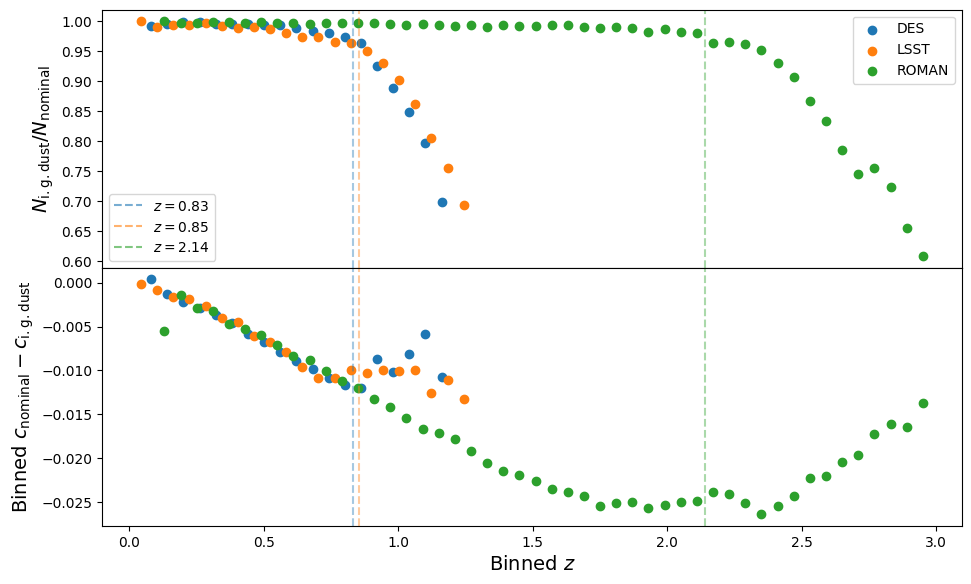

In [15]:
fig = plt.figure(figsize=(10,6))
ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.43])


z_drop_DES = plot_drop_top(DES[create_filt(DES)&(np.isin(DES['FIELD'],['X3','C3']))],DES_max[create_filt(DES_max)&(np.isin(DES_max['FIELD'],['X3','C3']))],label='DES')
z_drop_LSST = plot_drop_top(LSST[create_filt(LSST)&(LSST['FIELD']=='DDF')],LSST_max[create_filt(LSST_max)&(LSST_max['FIELD']=='DDF')],label='LSST')
z_drop_ROMAN = plot_drop_top(ROMAN[create_filt(ROMAN)&(np.isin(ROMAN['FIELD'],['DEEP']))],ROMAN_max[create_filt(ROMAN_max)&(np.isin(ROMAN_max['FIELD'],['DEEP']))],label='ROMAN')


legend1 = plt.legend(loc='upper right')
ax = plt.gca()
blue_dotted = mlines.Line2D([], [], linestyle="--",color='C0', label=f"$z={z_drop_DES:.2f}$",alpha=0.6)
orange_dotted = mlines.Line2D([], [], linestyle="--",color='C1', label=f"$z={z_drop_LSST:.2f}$",alpha=0.6)
green_dotted = mlines.Line2D([], [], linestyle="--",color='C2', label=f"$z={z_drop_ROMAN:.2f}$",alpha=0.6)
legend2 = ax.legend(handles=[blue_dotted,orange_dotted,green_dotted],loc='lower left')

ax.add_artist(legend1)

plt.axvline(x=z_drop_DES,c='C0',ls='--',alpha=0.4)
plt.axvline(x=z_drop_LSST,c='C1',ls='--',alpha=0.4)
plt.axvline(x=z_drop_ROMAN,c='C2',ls='--',alpha=0.4)

# plt.title("LSST Simulation",fontsize=16)
plt.ylabel("$N_\mathrm{i.g. dust}/N_\mathrm{nominal}$",fontsize=14)


ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.43])

plot_drop_bottom(DES[create_filt(DES)&(np.isin(DES['FIELD'],['X3','C3']))],DES_max[create_filt(DES_max)&(np.isin(DES_max['FIELD'],['X3','C3']))])
plot_drop_bottom(LSST[create_filt(LSST)&(LSST['FIELD']=='DDF')],LSST_max[create_filt(LSST_max)&(LSST_max['FIELD']=='DDF')])
plot_drop_bottom(ROMAN[create_filt(ROMAN)&(np.isin(ROMAN['FIELD'],['DEEP']))],ROMAN_max[create_filt(ROMAN_max)&(np.isin(ROMAN_max['FIELD'],['DEEP']))])

plt.axvline(x=z_drop_DES,c='C0',ls='--',alpha=0.4)
plt.axvline(x=z_drop_LSST,c='C1',ls='--',alpha=0.4)
plt.axvline(x=z_drop_ROMAN,c='C2',ls='--',alpha=0.4)


plt.xlabel("Binned $z$",fontsize=14)
plt.ylabel("Binned $c_\mathrm{nominal}-c_\mathrm{i.g. dust}$",fontsize=14)
# plt.savefig("pdfs/combined_sim_count_compare.pdf",bbox_inches='tight')
plt.show()